# Clustering: EM for a Gaussian mixture and k-means

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

from scipy.stats import multivariate_normal
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score
from ipywidgets import interact, IntSlider

We simulate three Gaussian populations and try to recover them without using the labels, in two ways: fitting a mixture of Gaussian distributions with the EM algorithm, by hand, and with k-means, by hand and with `sklearn`. At the end we look at how to choose the number of clusters.

## The data

In [2]:
m = 200

mu1, mu2, mu3 = ([3,3], [6,4.5], [9,6])
S1  = [[1, 0.7], [0.7, 1]]
S2  = [[1, -0.7], [-0.7, 1]]
S3  = [[1, 0.7], [0.7, 1]]

rng = np.random.default_rng(111)
X1 = rng.multivariate_normal(mean = mu1, cov = S1, size = m)
X2 = rng.multivariate_normal(mean = mu2, cov = S2, size = m)
X3 = rng.multivariate_normal(mean = mu3, cov = S3, size = m)

X = np.vstack([X1, X2, X3])
pob = np.repeat([1, 2, 3], m)   # population of each observation
n = len(X)

In [3]:
palette = ['#0072B2', '#E69F00', '#009E73', '#CC79A7', '#56B4E9', '#D55E00', '#B8A800', '#555555']

def plot_groups(ax, labels, names=None, size=5, alpha=0.8):
    for i, value in enumerate(np.unique(labels)):
        ax.plot(X[labels == value, 0], X[labels == value, 1], 'o', color=palette[i], markersize=size,
                markeredgecolor='white', markeredgewidth=0.4, alpha=alpha,
                label=None if names is None else f'{names} {value}')
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.25)

def plot_ellipse(ax, mean, cov, color, lw=2):
    # Ellipse with 95% of the probability of a Gaussian distribution
    values, vectors = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(vectors[1, -1], vectors[0, -1]))
    width, height = 2*np.sqrt(5.991*values[::-1])
    ax.add_patch(Ellipse(mean, width, height, angle=angle, facecolor='none', edgecolor=color, lw=lw))

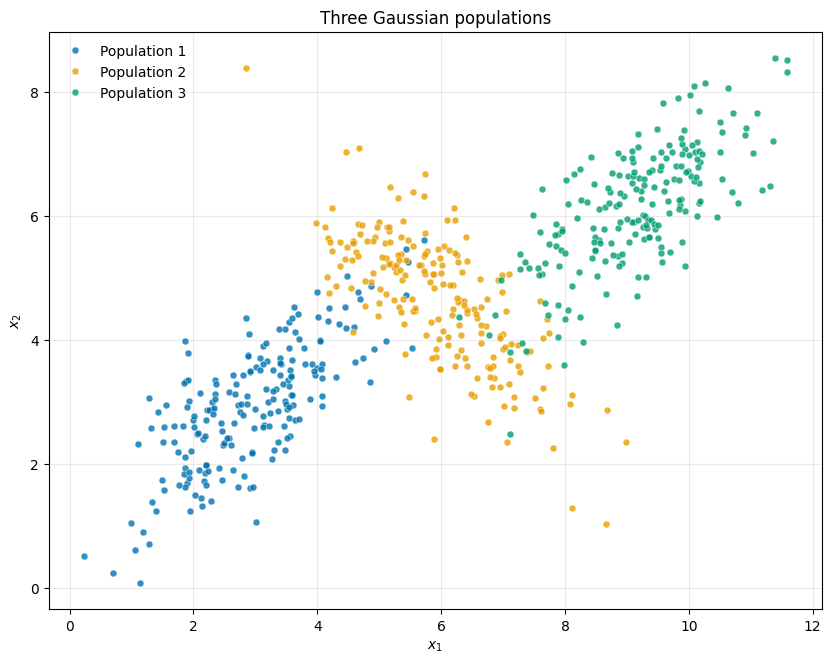

In [4]:
fig, ax = plt.subplots(figsize=(11, 7.5))
plot_groups(ax, pob, 'Population')
ax.set_title('Three Gaussian populations')
ax.legend(loc='upper left', frameon=False)

## EM algorithm for a mixture of Gaussian distributions

The model is $f(x) = \sum_k \pi_k\,\phi(x; \mu_k, \Sigma_k)$. Each iteration has two steps:

- **E step**: with the current parameters, compute the probability that each observation comes from each component, $w_{ik} = \pi_k\phi(x_i;\mu_k,\Sigma_k)/\sum_l\pi_l\phi(x_i;\mu_l,\Sigma_l)$.
- **M step**: update the proportions, means and covariance matrices as weighted versions of the usual estimators, with weights $w_{ik}$.

We start, on purpose, from three means that are far from the data and almost equal.

In [5]:
K = 3
hat_pis = np.array([1/3]*3)
hat_mus = np.array([[2, 9], [2.5, 9], [3, 9]], dtype=float)
hat_Ss = np.array([np.eye(2)]*3)

histo_mu = [hat_mus.copy()]
logver = []

delta  = 0.01 # tolerance
iterM  = 1000 # maximum of iterations
tolera = 1 # initialize tolerance
itera  = 1 # initialize iteration

while ((tolera > delta) & (itera < iterM)):
    itera = itera + 1

    hat_mus_old = hat_mus.copy()
    hat_Ss_old = hat_Ss.copy()

    # E step
    phis = np.vstack([multivariate_normal.pdf(X, mean = hat_mus[k], cov = hat_Ss[k]) for k in range(K)]).T

    num   = (hat_pis * phis)
    denom = num.sum(axis=1).reshape(n,1)
    w     = num / denom

    # M step
    hat_pis = np.mean(w, axis=0)
    for k in range(K):
        w_k = w[:,k].reshape(n,1)
        hat_mus[k] = (w_k * X).sum(axis=0) / w_k.sum()
        hat_Ss[k] = (w_k * (X-hat_mus[k])).T @ (X-hat_mus[k]) / w_k.sum()

    logver.append(np.log(num.sum(axis=1)).sum())
    histo_mu.append(hat_mus.copy())

    tolera = np.sum((hat_mus-hat_mus_old)**2) + np.sum((hat_Ss-hat_Ss_old)**2)

histo_mu = np.array(histo_mu)
print('Iterations:', itera)

Iterations: 36


The log-likelihood increases in every iteration. After a very large first step, when the means reach the data, it keeps improving slowly for many iterations while the three components sort out the three groups.

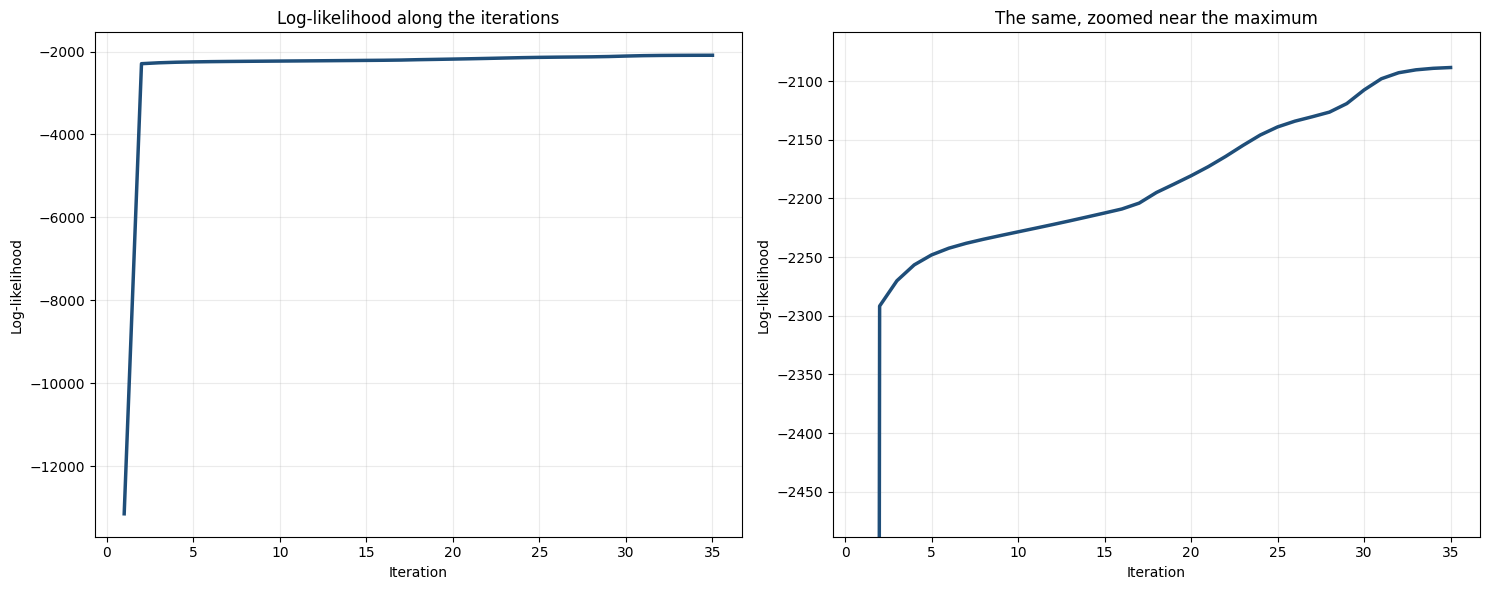

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].plot(range(1, len(logver)+1), logver, color='#1f4e79', lw=2.5)
axes[0].set_title('Log-likelihood along the iterations')
axes[1].plot(range(1, len(logver)+1), logver, color='#1f4e79', lw=2.5)
axes[1].set_ylim(np.max(logver)-400, np.max(logver)+30)
axes[1].set_title('The same, zoomed near the maximum')
for ax in axes:
    ax.set_xlabel('Iteration')
    ax.set_ylabel('Log-likelihood')
    ax.grid(True, alpha=0.25)
plt.tight_layout()

The estimated means and covariance matrices are close to the true ones:
$\mu_1 = (3, 3)$, $\mu_2 = (6, 4.5)$, $\mu_3 = (9, 6)$, with variances 1 and covariances 0.7, $-0.7$ and 0.7.

In [7]:
hat_mus

array([[2.94692809, 2.98652088],
       [6.00677081, 4.60623555],
       [9.13468032, 6.14739918]])

In [8]:
hat_Ss.round(4)

array([[[ 1.0223,  0.7991],
        [ 0.7991,  1.0954]],

       [[ 1.0519, -0.7984],
        [-0.7984,  1.1364]],

       [[ 1.0592,  0.7016],
        [ 0.7016,  0.9078]]])

In [9]:
predict_pob = w.argmax(axis=1) + 1

# The components are found in arbitrary order, we match each one with its most frequent true population
table = pd.crosstab(pd.Series(pob, name='Population'), pd.Series(predict_pob, name='Component of the mixture'))
table

Component of the mixture,1,2,3
Population,,,
1,191,9,0
2,6,190,4
3,0,9,191


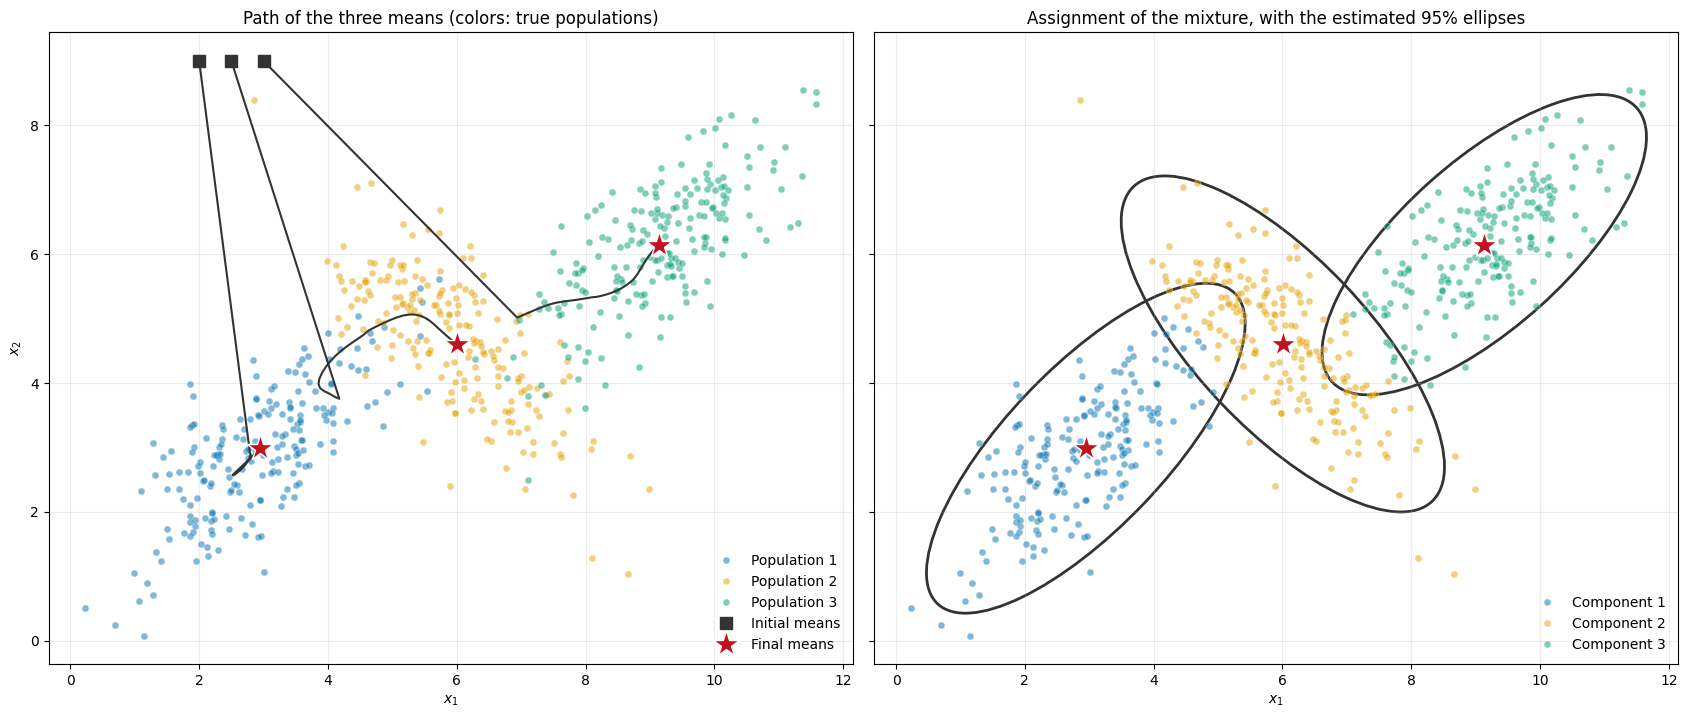

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7), sharey=True)

plot_groups(axes[0], pob, 'Population', alpha=0.5)
for k in range(K):
    axes[0].plot(histo_mu[:, k, 0], histo_mu[:, k, 1], '-', color='#333333', lw=1.5, zorder=4)
    axes[0].plot(histo_mu[0, k, 0], histo_mu[0, k, 1], 's', color='#333333', markersize=8, zorder=5,
                 label='Initial means' if k == 0 else None)
    axes[0].plot(histo_mu[-1, k, 0], histo_mu[-1, k, 1], '*', color='#c1121f', markersize=20, markeredgecolor='white',
                 zorder=6, label='Final means' if k == 0 else None)
axes[0].set_title('Path of the three means (colors: true populations)')
axes[0].legend(loc='lower right', frameon=False)

plot_groups(axes[1], predict_pob, 'Component', alpha=0.5)
for k in range(K):
    plot_ellipse(axes[1], hat_mus[k], hat_Ss[k], '#333333')
    axes[1].plot(hat_mus[k, 0], hat_mus[k, 1], '*', color='#c1121f', markersize=20, markeredgecolor='white', zorder=6)
axes[1].set_ylabel('')
axes[1].set_title('Assignment of the mixture, with the estimated 95% ellipses')
axes[1].legend(loc='lower right', frameon=False)
plt.tight_layout()

## k-means by hand

k-means can be seen as a simplified version of the previous algorithm: all the components have the same spherical covariance matrix, and each observation is assigned completely to one cluster instead of having a probability for each one. Each iteration (Lloyd's algorithm):

- assigns each observation to the closest centroid,
- moves each centroid to the mean of the observations assigned to it.

It minimizes the sum of squared distances of the observations to their centroid (SSE).

In [11]:
def k_means_step(X, centroids):
    distances = ((X[:, None, :] - centroids[None, :, :])**2).sum(axis=2)
    labels = distances.argmin(axis=1)
    new_centroids = np.array([X[labels == k].mean(axis=0) if np.any(labels == k) else centroids[k]
                              for k in range(len(centroids))])
    sse = distances.min(axis=1).sum()
    return labels, new_centroids, sse

# Same starting points as before
centroids = np.array([[2, 9], [2.5, 9], [3, 9]], dtype=float)
histo_centroids = [centroids]
histo_labels = []
histo_sse = []

for it in range(100):
    labels, new_centroids, sse = k_means_step(X, centroids)
    histo_labels.append(labels)
    histo_sse.append(sse)
    histo_centroids.append(new_centroids)
    if np.allclose(new_centroids, centroids):
        break
    centroids = new_centroids

print('Iterations:', len(histo_sse))
print('SSE:', histo_sse[-1])
centroids

Iterations: 11
SSE: 1054.4795854240913


array([[2.70870529, 2.75564574],
       [5.99373249, 4.60813092],
       [9.35118152, 6.34124463]])

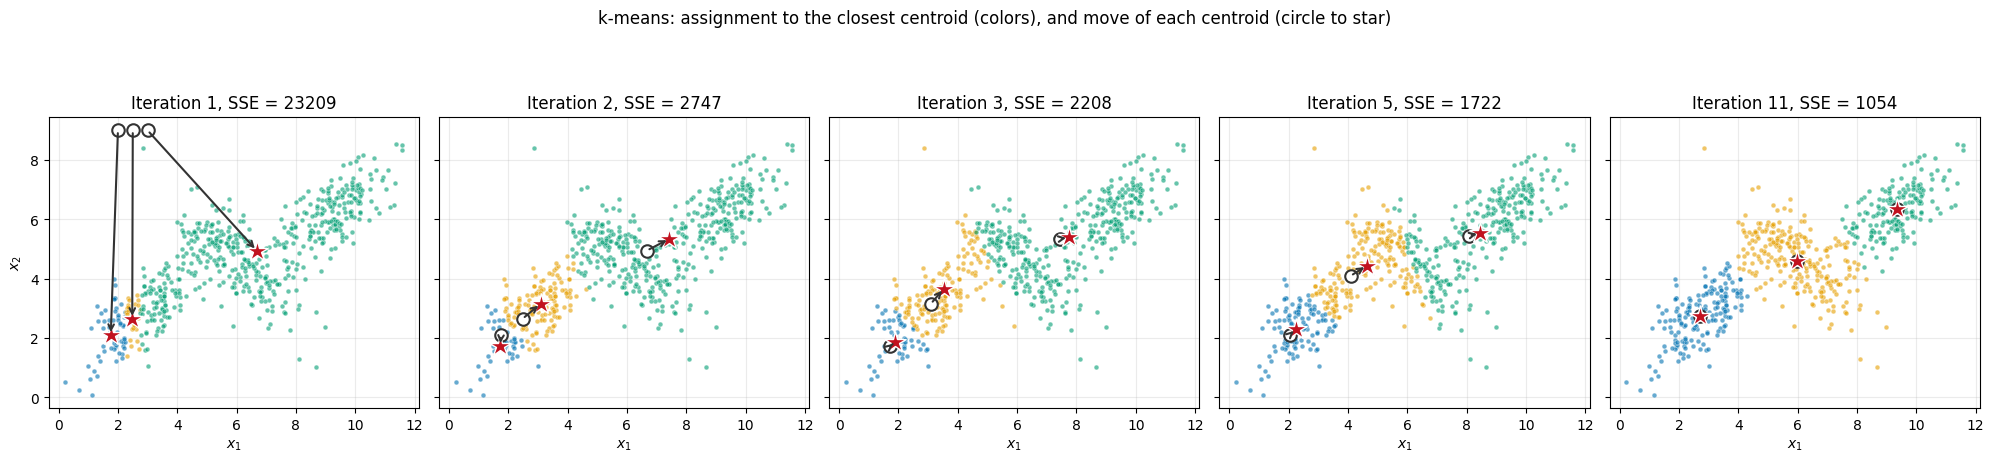

In [12]:
show = [0, 1, 2, 4, len(histo_labels)-1]
fig, axes = plt.subplots(1, 5, figsize=(20, 4.6), sharey=True)
for ax, it in zip(axes, show):
    plot_groups(ax, histo_labels[it], size=3.5, alpha=0.6)
    before, after = histo_centroids[it], histo_centroids[it+1]
    for k in range(K):
        ax.annotate('', after[k], before[k], arrowprops=dict(arrowstyle='->', color='#333333', lw=1.5))
        ax.plot(before[k, 0], before[k, 1], 'o', color='white', markersize=9, markeredgecolor='#333333', markeredgewidth=1.5)
        ax.plot(after[k, 0], after[k, 1], '*', color='#c1121f', markersize=16, markeredgecolor='white')
    ax.set_title(f'Iteration {it+1}, SSE = {histo_sse[it]:.0f}')
for ax in axes[1:]:
    ax.set_ylabel('')
fig.suptitle('k-means: assignment to the closest centroid (colors), and move of each centroid (circle to star)')
fig.tight_layout(rect=(0, 0, 1, 0.93))

## Using KMeans

In [13]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=111)
kmeans = kmeans.fit(X)

In [14]:
# The lowest SSE value
print('SSE:', kmeans.inertia_)

SSE: 1054.4795854240915


In [15]:
# Final locations of the centroid
kmeans.cluster_centers_

array([[9.35118152, 6.34124463],
       [2.70870529, 2.75564574],
       [5.99373249, 4.60813092]])

In [16]:
# The number of iterations required to converge
print('Iterations:', kmeans.n_iter_)

Iterations: 10


In [17]:
# Predicted labels
kmeans.labels_[:10]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 2], dtype=int32)

## Choosing the appropriate number of clusters

### The elbow of the SSE

The SSE always decreases when we add clusters. We look for the "elbow": the number of clusters after which the improvement becomes small.

In [18]:
# A list holds the SSE values for each k
k_values = np.arange(1, 11)
sse = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=111)
    kmeans.fit(X)
    sse.append(kmeans.inertia_)
sse = np.array(sse)

A simple way of locating the elbow: scale both axes to $[0, 1]$, and take the point of the curve farthest from the line that joins its two ends.

In [19]:
def elbow(k_values, sse):
    x_norm = (k_values - k_values[0])/(k_values[-1] - k_values[0])
    y_norm = (sse - sse[-1])/(sse[0] - sse[-1])
    # The line joins (0, 1) and (1, 0): the distance to it is proportional to 1 - x - y
    distance = 1 - x_norm - y_norm
    return k_values[np.argmax(distance)]

k_elbow = elbow(k_values, sse)
print('Elbow:', k_elbow)

Elbow: 3


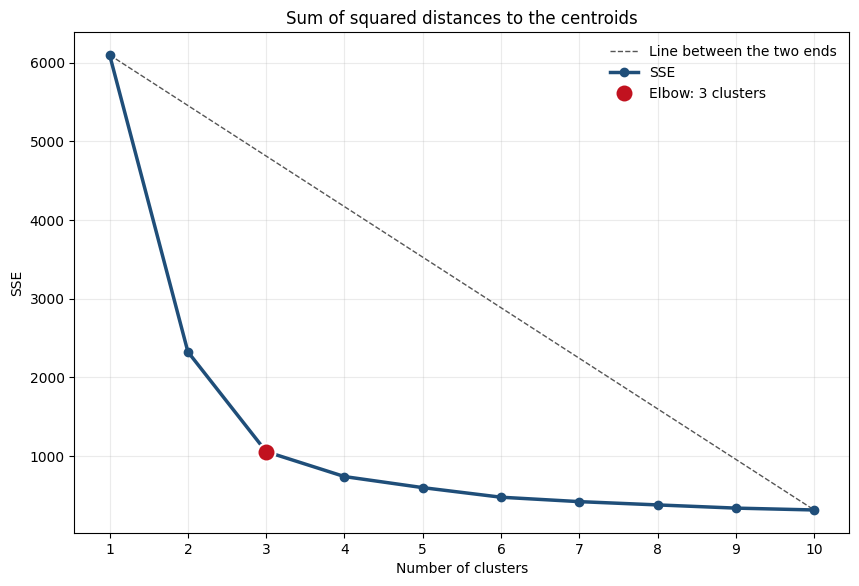

In [20]:
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.plot([k_values[0], k_values[-1]], [sse[0], sse[-1]], '--', color='#555555', lw=1, label='Line between the two ends')
ax.plot(k_values, sse, 'o-', color='#1f4e79', lw=2.5, label='SSE')
ax.plot(k_elbow, sse[k_elbow-1], 'o', color='#c1121f', markersize=13, markeredgecolor='white', markeredgewidth=1.5,
        label=f'Elbow: {k_elbow} clusters')
ax.set_xticks(k_values)
ax.set_xlabel('Number of clusters')
ax.set_ylabel('SSE')
ax.set_title('Sum of squared distances to the centroids')
ax.legend(loc='upper right', frameon=False)
ax.grid(True, alpha=0.25)

### The silhouette

For each observation, the silhouette compares $a$, its mean distance to the observations of its own cluster, with $b$, its mean distance to the observations of the closest other cluster: $s = (b-a)/\max(a, b)$. It is close to 1 when the observation is well inside its cluster, close to 0 when it is between two clusters, and negative when it would fit better in another one.

In the plots on the left each cluster is a block, with the silhouettes of its observations sorted; the dashed line is the average silhouette.

In [21]:
def plot_silhouette(k):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=111)
    kmeans.fit(X)
    silhouette_avg = silhouette_score(X, kmeans.labels_)

    # Compute the silhouette scores for each sample
    sample_silhouette_values = silhouette_samples(X, kmeans.labels_)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
    y_lower = 10
    for i in range(k):
        # Aggregate the silhouette scores for samples belonging to
        # cluster i, and sort them
        ith_cluster_silhouette_values = np.sort(sample_silhouette_values[kmeans.labels_ == i])

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        ax1.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_silhouette_values, facecolor=palette[i],
                          edgecolor=palette[i], alpha=0.8)

        # Label the silhouette plots with their cluster numbers at the middle
        ax1.text(-0.07, y_lower + 0.5 * size_cluster_i, str(i), va='center')

        # Compute the new y_lower for next plot
        y_lower = y_upper + 10  # 10 for the 0 samples

    ax1.set_title(f'{k} clusters: average silhouette = {silhouette_avg:.3f}')
    ax1.set_xlabel('Silhouette coefficient')
    ax1.set_ylabel('Cluster')

    # The vertical line for average silhouette score of all the values
    ax1.axvline(x=silhouette_avg, color='#c1121f', linestyle='--')
    ax1.set_yticks([])  # Clear the yaxis labels / ticks
    ax1.set_xlim(-0.15, 1)
    ax1.grid(True, axis='x', alpha=0.25)

    # 2nd Plot showing the actual clusters formed
    plot_groups(ax2, kmeans.labels_, size=4, alpha=0.7)
    for i, c in enumerate(kmeans.cluster_centers_):
        ax2.plot(c[0], c[1], 'o', color='white', markersize=17, markeredgecolor='#333333', markeredgewidth=1.5, zorder=5)
        ax2.text(c[0], c[1], str(i), ha='center', va='center', fontsize=10, fontweight='bold', zorder=6)
    ax2.set_title('The clusters, with their centroids')
    plt.tight_layout()
    plt.show()
    return silhouette_avg

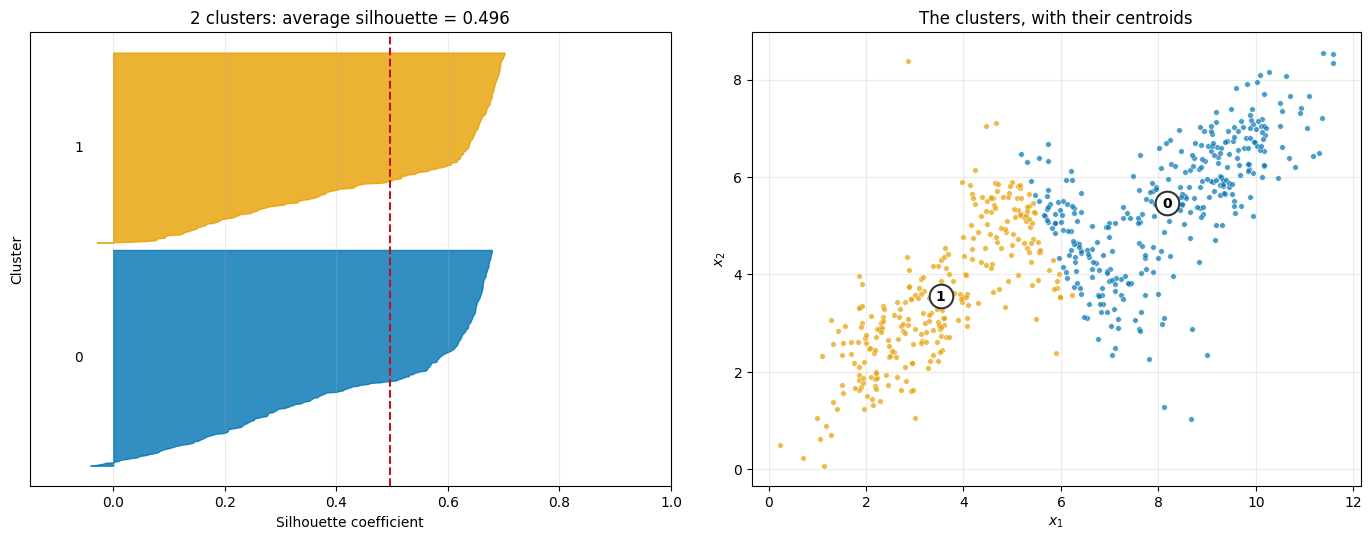

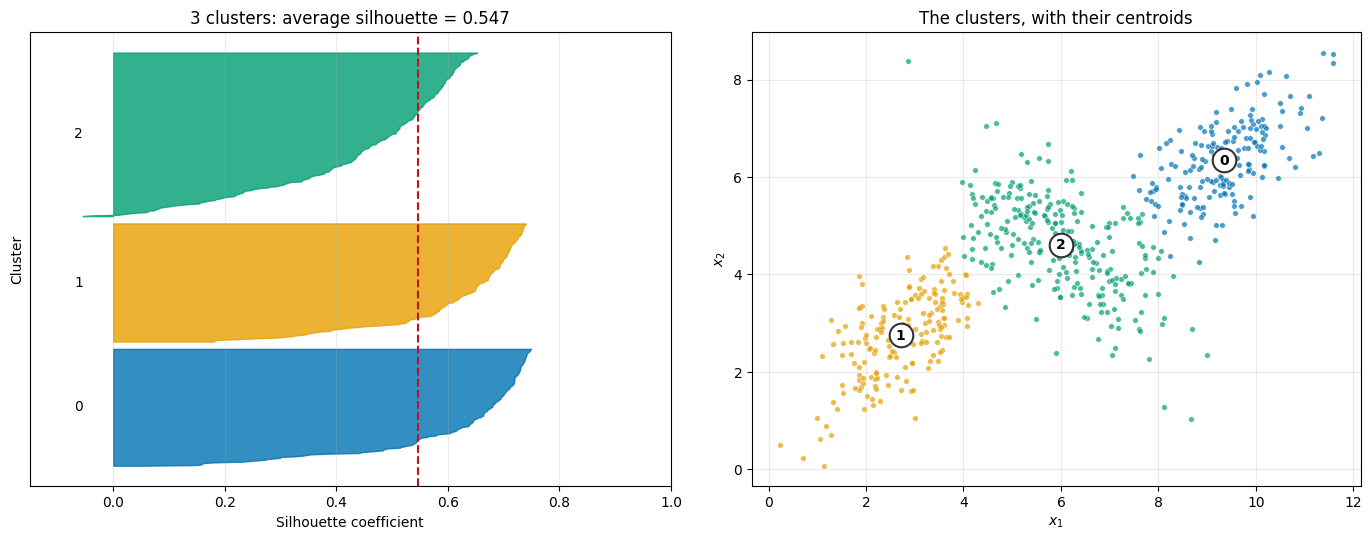

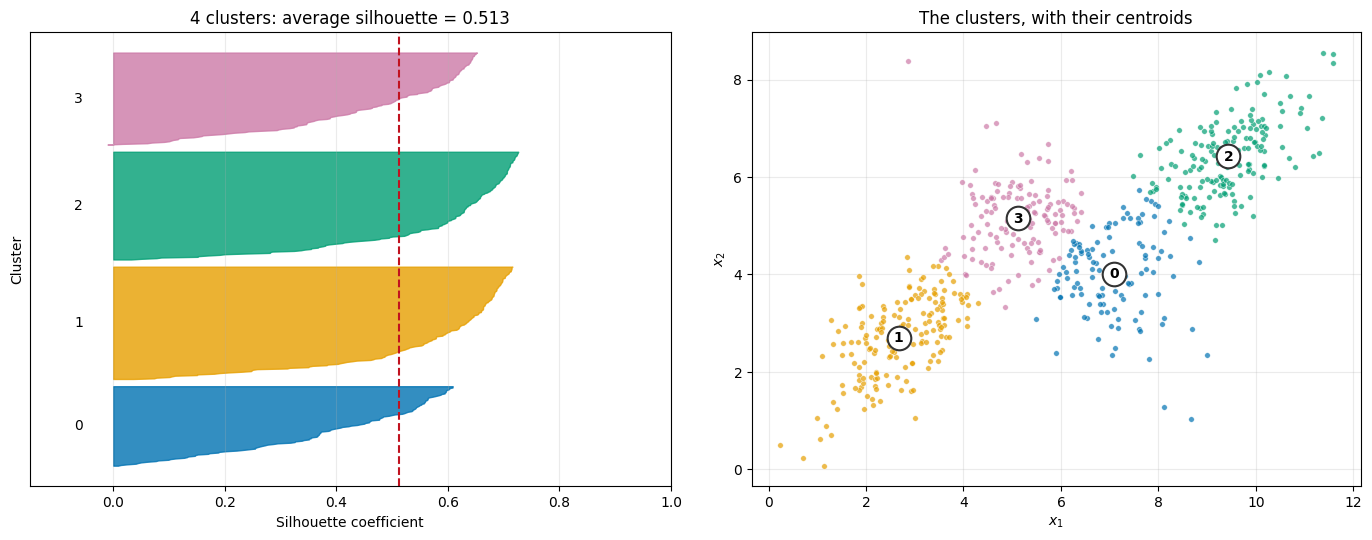

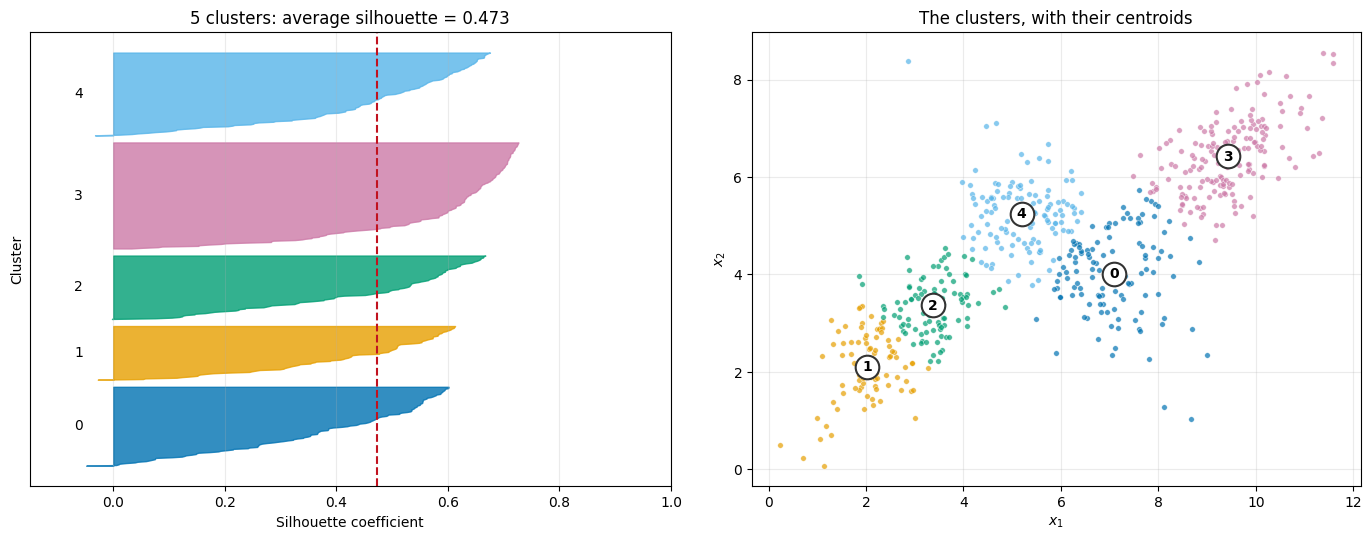

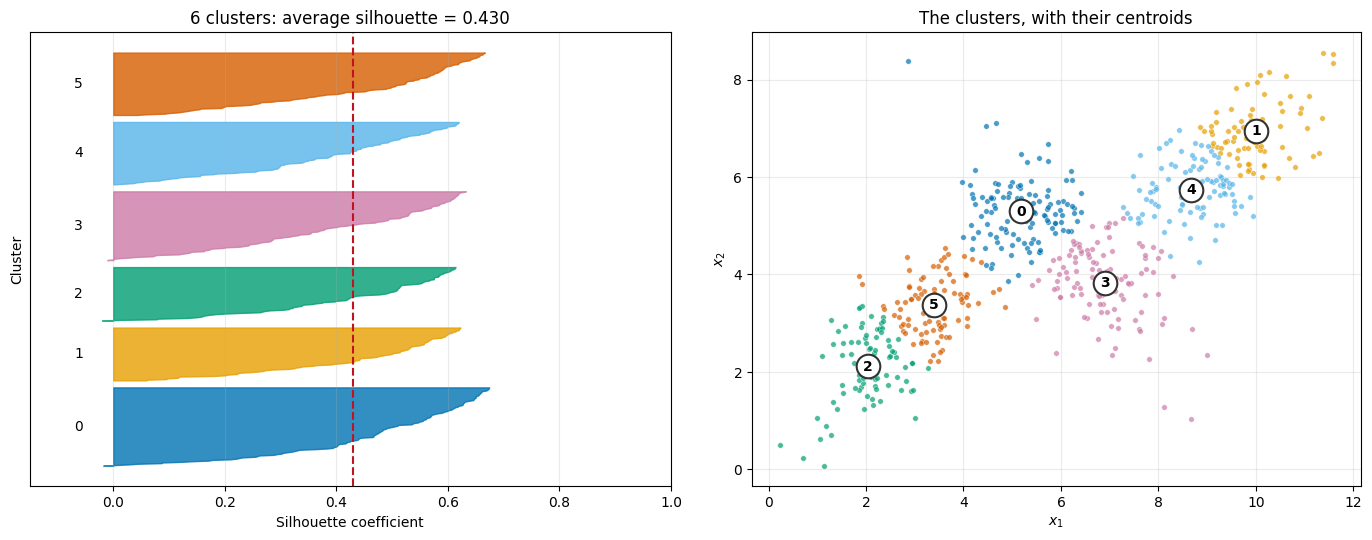

In [22]:
silhouette_avgs = []
kmax = 7

for k in range(2, kmax):
    silhouette_avgs.append(plot_silhouette(k))

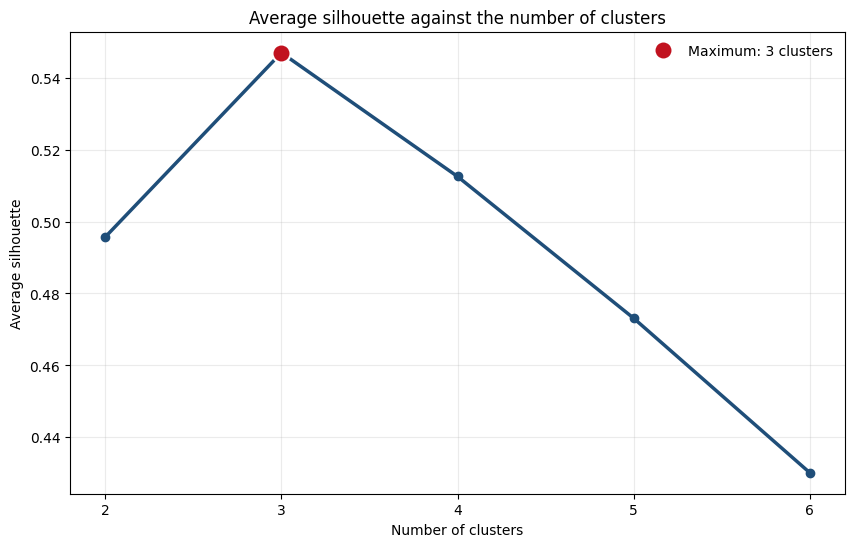

In [23]:
best_k = int(np.argmax(silhouette_avgs)) + 2

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(range(2, kmax), silhouette_avgs, 'o-', color='#1f4e79', lw=2.5)
ax.plot(best_k, max(silhouette_avgs), 'o', color='#c1121f', markersize=13, markeredgecolor='white', markeredgewidth=1.5,
        label=f'Maximum: {best_k} clusters')
ax.set_xticks(range(2, kmax))
ax.set_xlabel('Number of clusters')
ax.set_ylabel('Average silhouette')
ax.set_title('Average silhouette against the number of clusters')
ax.legend(loc='upper right', frameon=False)
ax.grid(True, alpha=0.25)

## The effect of the number of clusters

Move the slider to change the number of clusters (this cell needs a running kernel).

In [24]:
def plot_k(ax, k):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=111).fit(X)
    plot_groups(ax, kmeans.labels_, size=4, alpha=0.7)
    ax.plot(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], '*', color='#c1121f', markersize=18,
            markeredgecolor='white')
    ax.set_title(f'{k} clusters, SSE = {kmeans.inertia_:.0f}')

def interactive_k(k):
    fig, ax = plt.subplots(figsize=(11, 7.5))
    plot_k(ax, k)
    plt.show()

interact(interactive_k, k=IntSlider(value=3, min=1, max=8, description='clusters'));

interactive(children=(IntSlider(value=3, description='clusters', max=8, min=1), Output()), _dom_classes=('widg…

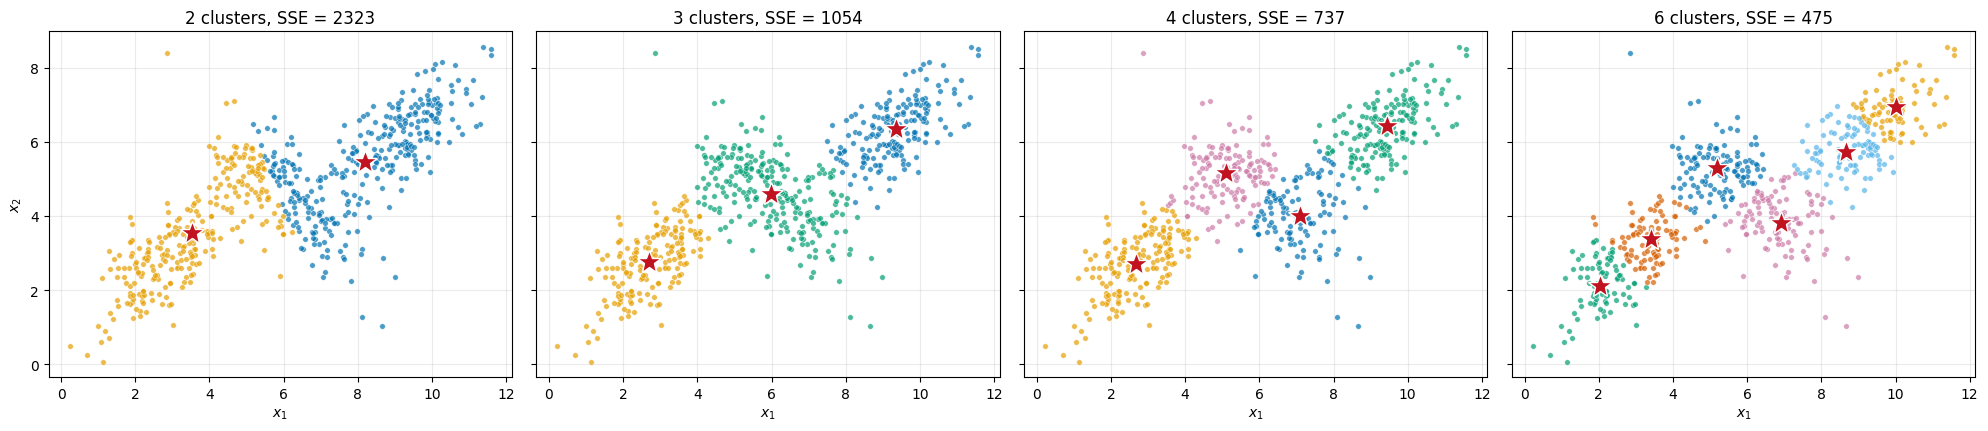

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)
for ax, k in zip(axes, [2, 3, 4, 6]):
    plot_k(ax, k)
for ax in axes[1:]:
    ax.set_ylabel('')
plt.tight_layout()